# HW5 : 전처리 재현 + 질문 셋

- 21011658 김영헌
- 입력 : `sales_data.csv` (집현캠퍼스, 수업과 같은 파일)
- 단계 ① ~ ④ : 수업 2차시 전처리를 그대로 다시 함 → `sales_clean.csv` 저장
- 단계 ⑤ ~ ⑦ : 정리된 `df` 로 새 질문 셋. 질문 → 그림 또는 표 → 답 두 줄

### 준비 : 한글 글꼴
그림 제목의 한글이 네모로 나오지 않게 노트북 맨 처음에 한 번만 실행

In [1]:
import matplotlib.pyplot as plt
import platform
import pandas as pd

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}  # 운영체제별 한글 글꼴
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False  # 음수 부호가 네모로 나오는 것 방지

## 단계 ① 읽고 날짜 세 칸을 날짜로
글자(str)로 읽힌 날짜 세 칸을 `pd.to_datetime` 으로 바꿈. 바꿔야 날짜끼리 빼고 비교할 수 있음

In [2]:
df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

## 단계 ② 중복 행 제거
14 칸이 소수점까지 모두 같은 줄 26 쌍은 같은 주문이 두 번 들어간 것. 뒤쪽 줄을 지우고 결과를 `df` 에 다시 넣음

결측치 세 칸 (customer_age 51 · satisfaction 30 · delivery_date 5) 은 수업과 같이 **그대로 둠** (채우면 없던 봉우리가 생김)

In [3]:
before = len(df)
df = df.drop_duplicates()  # 다시 df 에 넣어야 반영됨
print(before, "->", len(df))

1030 -> 1004


## 단계 ③ 수량 > 100 인 줄의 수량을 금액 ÷ 단가로 복원
수량 > 100 인 22 줄은 금액 ≠ 수량 × 단가 인 22 줄과 같은 줄이고, 금액 ÷ 단가가 전부 딱 떨어지는 정수 → 틀린 칸은 수량. 지우지 않고 수량만 고쳐 넣음

In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


## 단계 ④ date_error 표시, sales_clean.csv 저장
도착일 < 배송일 인 줄은 두 날짜 중 어느 쪽이 틀렸는지 알려 주는 칸이 없음 → 고치지 않고 `date_error = True` 로 표시만 함. 배송 기간을 물을 때 (단계 ⑤) 이 줄을 뺌

원본 `sales_data.csv` 는 덮어쓰지 않고 새 파일로 저장. `index=False` 로 줄 번호는 넣지 않음

In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].value_counts())

df.to_csv("sales_clean.csv", index=False)
df.shape

date_error
False    857
True     147
Name: count, dtype: int64


(1004, 15)

### 단계 ① ~ ④ 정리

| 점검 | 처리 | 전 | 후 | 근거 |
|---|---|---|---|---|
| 결측치 51 · 30 · 5 | 유지 | 979 / 1000 / 1025 | 같음 | 채우면 없던 봉우리가 생김 |
| 중복 26 쌍 | 뒤쪽 제거 | 1,030 줄 | 1,004 줄 | 14 칸이 소수점까지 같음 |
| 금액 ≠ 수량 × 단가 22 건 | 수량을 금액 ÷ 단가로 복원 | 최대 990 | 최대 99, 불일치 0 | 나눈 값이 전부 정수 |
| 수량 > 150 22 건 | 위와 같은 줄 | 22 | 0 | 두 규칙이 같은 줄 |
| 도착일 < 배송일 | date_error 표시 | 없음 | 147 True | 판단 근거 없음 |

## 단계 ⑤ 배송 기간 (도착일 − 배송일) 은 보통 며칠인가
date_error 가 아닌 줄만 골라 날짜를 빼고 `.dt.days` 로 일수를 구한 뒤 히스토그램

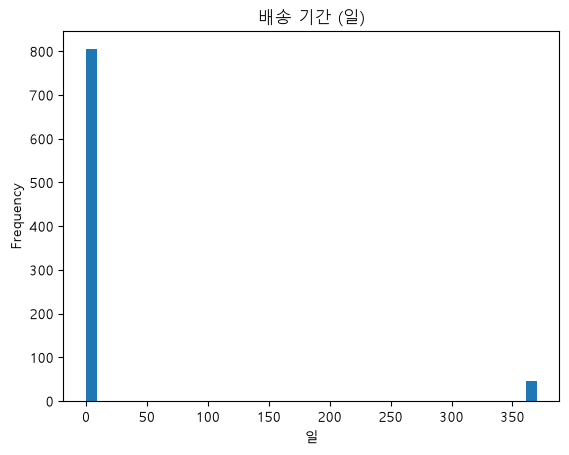

평균 : 22.05  중앙값 : 2.0


In [6]:
ok = df[~df["date_error"]]
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days  # 도착일 빈 5 줄은 NaN 으로 자동 제외

days.plot.hist(bins=40, title="배송 기간 (일)")
plt.xlabel("일")
plt.show()

print("평균 :", round(days.mean(), 2), " 중앙값 :", days.median())

평균 (22 일) 과 중앙값 (2 일) 이 크게 다름. 히스토그램 오른쪽 끝 360 일 근처에 따로 떨어진 덩어리가 평균을 끌어올림 → 그 줄을 들여다봄

In [7]:
far = days > 300
print("덩어리 줄 수 :", far.sum())
print("일수 :", sorted(days[far].astype(int).unique().tolist()))
ok.loc[far, ["order_date", "shipping_date", "delivery_date", "status"]].head(8)

덩어리 줄 수 : 47
일수 : [364, 365, 366, 367, 368, 369, 370]


,order_date,shipping_date,delivery_date,status
11,2023-01-12,2023-01-15,2024-01-15,배송완료
20,2023-01-21,2023-01-23,2024-01-27,배송완료
29,2023-01-30,2023-02-03,2024-02-03,배송완료
41,2023-02-11,2023-02-14,2024-02-17,배송완료
68,2023-03-10,2023-03-14,2024-03-12,배송완료
99,2023-04-10,2023-04-11,2024-04-12,배송완료
110,2023-04-21,2023-04-25,2024-04-24,배송완료
131,2023-05-12,2023-05-13,2024-05-16,배송완료


364 ~ 370 일 = 1 년 + (−1 ~ 5 일). 주문일 · 배송일은 그대로인데 도착일의 **연도만 1 년 뒤**로 적힌 것으로 보임. 도착일에서 1 년을 빼서 확인

In [8]:
back = ok.loc[far, "delivery_date"] - pd.DateOffset(years=1)  # 도착일 연도를 1 년 앞으로
gap = (back - ok.loc[far, "shipping_date"]).dt.days
print("1 년 뺀 뒤 일수 :", gap.value_counts().sort_index().to_dict())
print("배송일 최대 :", df["shipping_date"].max().date(), " 덩어리 도착일 최대 :", ok.loc[far, "delivery_date"].max().date())

1 년 뺀 뒤 일수 : {-2: 2, -1: 5, 0: 10, 1: 10, 2: 8, 3: 5, 4: 5, 5: 2}
배송일 최대 : 2025-09-29  덩어리 도착일 최대 : 2026-09-14


1 년을 빼면 나머지 줄과 같은 −2 ~ 5 일 범위로 들어감 (일부는 date_error 와 같은 −2 · −1). 연도 오기로 판단 → 이 47 줄은 배송 기간 계산에서 **뺌** (date_error 처럼 표시만 하고 지우지 않음. `df` 와 `sales_clean.csv` 는 그대로)

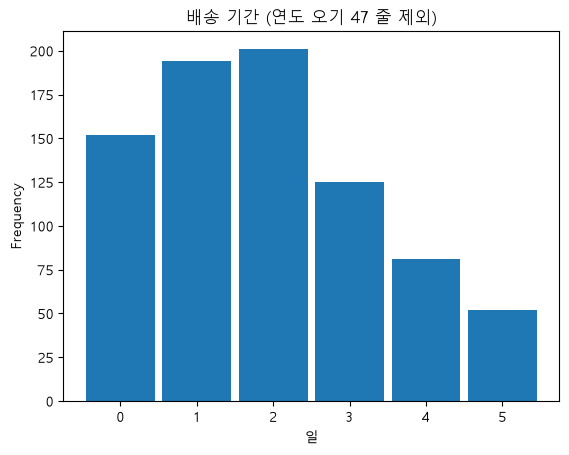

줄 수 : 805  평균 : 1.93  중앙값 : 2.0


In [9]:
days_ok = days[~far]

days_ok.plot.hist(bins=[x - 0.5 for x in range(0, 7)], rwidth=0.9, title="배송 기간 (연도 오기 47 줄 제외)")  # 막대 가운데가 0 ~ 5 일
plt.xlabel("일")
plt.show()

print("줄 수 :", days_ok.count(), " 평균 :", round(days_ok.mean(), 2), " 중앙값 :", days_ok.median())

**답 ⑤**
- 보통 배송 기간은 **2 일** (중앙값 2, 제외 뒤 평균 1.93). 0 ~ 5 일 안에 모두 들어감
- 처음 평균 22.05 일은 도착일 연도가 1 년 뒤로 적힌 47 줄 (364 ~ 370 일) 때문. 1 년을 빼면 −2 ~ 5 일로 돌아오므로 연도 오기로 보고 배송 기간 계산에서 뺌

## 단계 ⑥ 만족도가 낮을수록 반품이 많은가
`status == "반품"` 은 True / False 이므로 만족도별 `mean()` × 100 = 반품 비율 (%). 만족도 빈칸 30 줄은 자동으로 빠짐

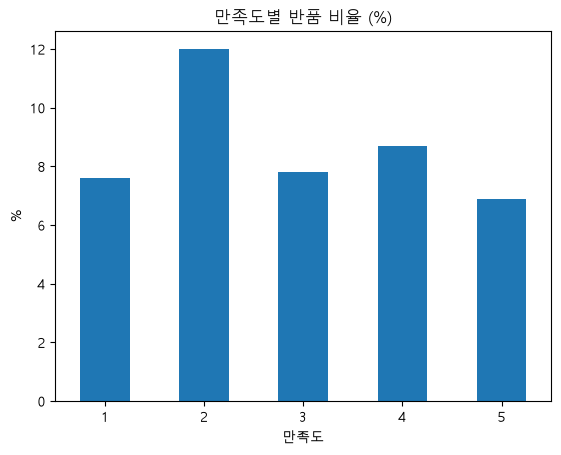

satisfaction
1     7.6
2    12.0
3     7.8
4     8.7
5     6.9
Name: status, dtype: float64
전체 반품 비율 : 8.6 %


In [10]:
is_return = df["status"] == "반품"
rate = (is_return.groupby(df["satisfaction"]).mean() * 100).round(1)
rate.index = rate.index.astype(int)  # 1.0 -> 1

rate.plot.bar(title="만족도별 반품 비율 (%)", rot=0)
plt.xlabel("만족도")
plt.ylabel("%")
plt.show()

print(rate)
print("전체 반품 비율 :", round(is_return.mean() * 100, 1), "%")

**답 ⑥**
- **아니다.** 반품 비율은 1점 7.6 %, 2점 12.0 %, 3점 7.8 %, 4점 8.7 %, 5점 6.9 % 로 만족도가 낮아질수록 늘어나지 않음
- 가장 높은 것은 2점 (12.0 %) 이고 1점 (7.6 %) 은 5점 (6.9 %) 과 0.7 %p 차이. 전체 평균 8.6 % 근처에서 오르내릴 뿐

## 단계 ⑦ 카테고리 매출 1위의 이유는 건수 · 단가 · 수량 중 무엇인가
카테고리별 건수 · 매출 합 · 평균 단가 · 평균 수량을 한 표로

In [11]:
table = df.groupby("category").agg(
    건수=("total_sales", "size"),
    매출합_억=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean"),
)
table["매출합_억"] = table["매출합_억"] / 1e8  # 억 원 단위
table = table.sort_values("매출합_억", ascending=False).round(1)
table

,건수,매출합_억,평균단가,평균수량
category,,,,
가구,213,28.4,257322.9,51.0
식품,210,25.1,255232.9,47.3
전자제품,207,24.7,249651.6,48.0
도서,204,24.5,238500.6,49.5
의류,170,21.8,249447.2,51.6


**답 ⑦**
- 1위 가구 (28.4 억) 와 5위 의류 (21.8 억) 의 차이는 **건수** : 213 건 vs 170 건 (약 25 % 많음). 평균 단가 (25.7 만 vs 24.9 만) · 평균 수량 (51.0 vs 51.6) 은 거의 같음
- 가구는 건수 1위 · 평균 단가 1위지만 평균 수량은 의류보다 적음 → 1위의 이유는 주문이 많이 들어온 것 (건수)